# Diagnostics

A prediction interval is a claim, and `conformalforecast.diagnostics` is how you
check it. This page covers the two ways to run an evaluation, the metrics worth
looking at, and the one measurement that will lie to you.

## The two modes

Both take the fitted object a method's `calibrate` / `calibrate_cv` returns.

- **`evaluate(fitted, histories, truths)`** — roll the fitted object over
  held-out windows it has never seen. This is the honest one.
- **`evaluate_calibration(fitted)`** — replay the method's own calibration data
  through the state its own calibration implied at each window. Cheap, requires
  no holdout, and **in sample** — so it is flattered by construction and does not
  track the target. Treat it as a plumbing check, never as a result.

Both return a `Report`.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import AutoETS

from conformalforecast import (
    AdaptiveConformalInference,
    ConformalizedQuantileRegression,
    SplitConformal,
)
from conformalforecast.adapters import StatsForecastAdapter
from conformalforecast.diagnostics import (
    coverage_by_horizon,
    coverage_by_series,
    coverage_width_summary,
    evaluate,
    evaluate_calibration,
    mean_interval_width,
    rolling_coverage,
    winkler_score,
)

HORIZON, SEASON, ALPHA = 12, 12, 0.1

df = pd.read_csv("nbs/data/air_passengers.csv", parse_dates=["ds"])
panel = df["y"].to_numpy()[None, :]

N_HOLDOUT = 5
train_end = panel.shape[1] - N_HOLDOUT * HORIZON
train_df = df.iloc[:train_end].reset_index(drop=True)

sf = StatsForecast(models=[AutoETS(season_length=SEASON)], freq="MS", n_jobs=1)
sf.fit(train_df)
forecaster = StatsForecastAdapter(
    sf=sf, train_df=train_df, horizon=HORIZON, freq="MS", model_name="AutoETS"
)

histories, truths = [], []
for k in range(N_HOLDOUT):
    end = panel.shape[1] - (N_HOLDOUT - k) * HORIZON
    histories.append(panel[:, :end])
    truths.append(panel[:, end : end + HORIZON])
truths = np.stack(truths, axis=1)
print("holdout truths", truths.shape, "(n_series, n_windows, horizon)")

holdout truths (1, 5, 12) (n_series, n_windows, horizon)


## The optimistic measurement

The two disagree, and the size of the gap is the point. Run both against the
same fitted method: `evaluate_calibration` replays the windows the method
calibrated on, `evaluate` rolls it over a holdout it has never seen.

In [ ]:
split = SplitConformal(alpha=ALPHA).calibrate_cv(forecaster, n_windows=24)

in_sample = evaluate_calibration(split)
out_of_sample = evaluate(split, histories, truths)

print(f"{'in sample (evaluate_calibration)':34s} {in_sample.marginal_coverage:6.1%}")
print(f"{'held out (evaluate)':34s} {out_of_sample.marginal_coverage:6.1%}")
print(f"{'target':34s} {1 - ALPHA:6.1%}")

in sample (evaluate_calibration)    95.8%
held out (evaluate)                 76.7%
target                              90.0%


Nineteen points apart, and the flattering number is the one that needs no
holdout. An interval that looks well above target on its own calibration data is
under-covering badly on data it has not seen.

::: {.callout-warning}
## `evaluate_calibration` is a smoke test, not a result

It scores the method on the very windows it calibrated on, so it is measuring
how well a quantile fits the sample it was taken from. For split conformal the
answer is "by construction, about right" — which tells you the plumbing works and
nothing about whether the interval will hold next month.

Online methods are flattered further still: the replay is in sample with respect
to the state that adapted on that same stream. SPCI is the extreme case — its
interval is conditional on the residual window immediately before the step, so
its replay re-queries each window's own history rather than broadcasting the
final answer. Because its quantile regressors were fit on the very residual rows
that replay then queries, the figure can sit near 100% while a holdout puts the
same method well below target — so for SPCI in particular, do not read the
number as coverage. Windows it cannot reach that way, the first `window_size` of
each series, are excluded rather than counted as misses;
`Report.n_evaluated_cells` says how many cells the numbers came from.

Use it to check that a pipeline runs. Report `evaluate`.
:::

## What a report contains

In [ ]:
print(out_of_sample.summary())

Report — SplitConformal
  target coverage: 0.900
  marginal coverage: 0.767
  coverage by horizon: [1.000, 1.000, 0.800, 1.000, 0.800, 0.400, 0.200, 0.200, 0.800, 1.000, 1.000, 1.000]
  mean width: 86.871
  mean Winkler score: 151.761
  n_holdout_samples: 5


`summary()` is the human-readable digest. The `Report` object also carries the
raw `intervals`, `truths` and `points` arrays, so any metric the module exposes
can be recomputed from it — which is what the rest of this page does.

## Coverage, sliced

Marginal coverage is one number over every cell. It is the headline, and it hides
the two things most likely to be wrong.

by series  [0.767]
by horizon [1.  1.  0.8 1.  0.8 0.4 0.2 0.2 0.8 1.  1.  1. ]


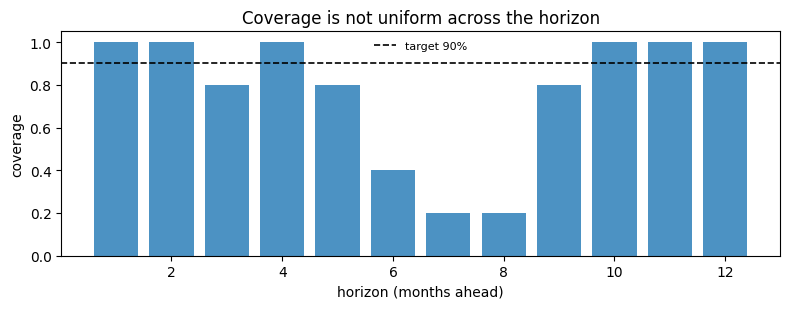

In [ ]:
interval, truth = out_of_sample.intervals, out_of_sample.truths

by_horizon = coverage_by_horizon(interval, truth)
by_series = coverage_by_series(interval, truth)

print("by series ", np.round(by_series, 3))
print("by horizon", np.round(by_horizon, 3))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(np.arange(1, HORIZON + 1), by_horizon, color="C0", alpha=0.8)
ax.axhline(1 - ALPHA, color="k", lw=1.2, ls="--", label=f"target {1 - ALPHA:.0%}")
ax.set_xlabel("horizon (months ahead)")
ax.set_ylabel("coverage")
ax.set_ylim(0, 1.05)
ax.set_title("Coverage is not uniform across the horizon")
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()

This is what "marginal, not conditional" means in practice. The 76.7% headline is
an average over wildly unequal parts: steps 1 to 5 and 9 to 12 are at or near
100%, while steps 7 and 8 cover 20%. Nothing about the marginal figure would have
told you that the interval essentially fails at the summer peak.

If your decision depends on a specific lead time, that lead time's bar is your
coverage — not the headline.

## Width, and why coverage alone is useless

A very large interval can cover everything, so any coverage number has to
be read next to a width.

In [ ]:
widths = mean_interval_width(interval)
print("mean width per (series, horizon):", np.round(widths[0], 1))

summary = coverage_width_summary(interval, truth, alpha=ALPHA)
for key, value in summary.items():
    print(f"{key:20s} {value:9.3f}")

mean width per (series, horizon): [ 51.2  54.   63.5  70.   78.1  85.2  89.3 102.8 104.3 109.7 113.6 120.7]
marginal_coverage        0.767
target_coverage          0.900
mean_width              86.871
mean_winkler           151.761


The **Winkler score** puts both on one scale: it charges the width of the
interval, plus a penalty of `2/alpha` times how far outside it the truth landed.
Lower is better, and unlike coverage it cannot be gamed by widening.

In [ ]:
scores = winkler_score(interval, truth, alpha=ALPHA)
print("Winkler per cell:", scores.shape, "-> mean", scores.mean().round(1))

Winkler per cell: (1, 5, 12) -> mean 151.8


## Comparing methods

The point of a single-number score is that it ranks. Here are three methods on
the same holdout.

In [ ]:
cqr = ConformalizedQuantileRegression(alpha=ALPHA).calibrate_cv(forecaster, n_windows=24)
aci = AdaptiveConformalInference(alpha=ALPHA, gamma=0.01).calibrate_cv(forecaster, n_windows=24)

reports = {}
for name, candidate in [("SplitConformal", split), ("CQR", cqr), ("ACI", aci)]:
    reports[name] = evaluate(candidate, histories, truths)

print(f"{'method':16s}{'coverage':>10s}{'width':>10s}{'Winkler':>10s}")
for name, report in reports.items():
    print(
        f"{name:16s}{report.marginal_coverage:9.1%}"
        f"{report.mean_interval_width:10.1f}{report.mean_winkler_score:10.1f}"
    )

method            coverage     width   Winkler
SplitConformal      76.7%      86.9     151.8
CQR                 88.3%     108.1     136.6
ACI                 80.0%      91.3     135.0


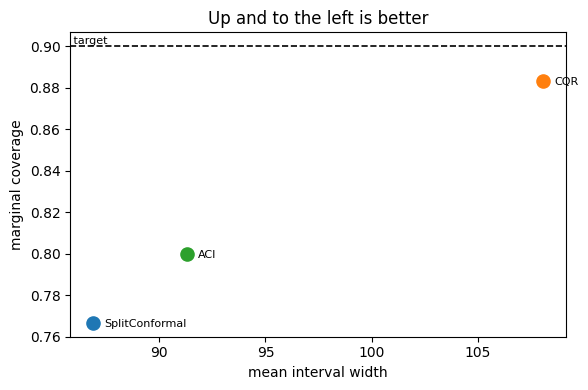

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
for i, (name, report) in enumerate(reports.items()):
    ax.scatter(
        report.mean_interval_width,
        report.marginal_coverage,
        s=90,
        color=f"C{i}",
        label=name,
        zorder=3,
    )
    ax.annotate(
        name,
        (report.mean_interval_width, report.marginal_coverage),
        textcoords="offset points",
        xytext=(8, -3),
        fontsize=8,
    )
ax.axhline(1 - ALPHA, color="k", lw=1.2, ls="--")
ax.text(ax.get_xlim()[0], 1 - ALPHA, " target", va="bottom", fontsize=8)
ax.set_xlabel("mean interval width")
ax.set_ylabel("marginal coverage")
ax.set_title("Up and to the left is better")
fig.tight_layout()

Read this plot the way you would read a Pareto front: up is valid, left is
useful, and the dashed line is the promise you made.

All three sit below it here, which is the honest outcome — AirPassengers trends
hard, five years of holdout is a genuine distribution shift, and no method on
this page gets a free pass from that. The ranking is still informative, and nothing
dominates: split conformal is the narrowest (86.9) and covers worst (76.7%), CQR
covers best (88.3%) and is the widest (108.1), and ACI sits between them on both.
ACI wins the Winkler score because a 5% width premium over split conformal bought
it a 3-point coverage gain, and Winkler prices that trade for you. That is the
argument for a scalar score: the scatter shows you there is a trade-off, and the
score tells you which side of it to be on.

## Coverage over time

For an online method the question is not "what was the coverage" but "when was
it wrong". `rolling_coverage` answers that, with one shape subtlety worth
knowing first.

In [ ]:
aci_report = reports["ACI"]
print("intervals", aci_report.intervals.shape, " truths", aci_report.truths.shape)
print(
    "rolling_coverage ->", rolling_coverage(aci_report.intervals, aci_report.truths, window=3).shape
)

intervals (1, 5, 12, 2)  truths (1, 5, 12)
rolling_coverage -> (1, 3, 12)


It reduces the **samples** axis and leaves the horizon axis alone:
`(n_series, n_samples - window + 1, horizon)`. Five holdout windows with a window
of 3 therefore gives 3 values for *each* of the 12 horizon steps, not one line.

What we want is calendar time. The five holdout windows are contiguous,
non-overlapping 12-month blocks in chronological order, so their 60 cells *are*
the last 60 months of the series. Reshaping to one month per sample turns the
rolling window into a rolling **year**.

49 rolling values, from 50% to 100%


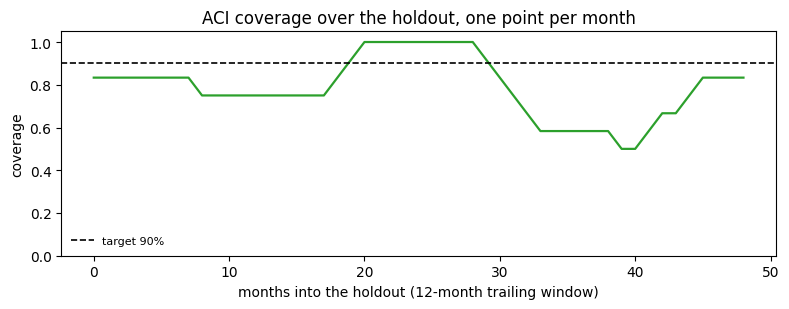

In [ ]:
# Each holdout window is the 12 months following the previous one, so flattening
# (window, horizon) recovers the last 60 months in order.
months_iv = aci_report.intervals.reshape(1, -1, 1, 2)
months_truth = aci_report.truths.reshape(1, -1, 1)
np.testing.assert_allclose(months_truth[0, :, 0], panel[0, train_end:])

window = 12
rolling = rolling_coverage(months_iv, months_truth, window=window)[0, :, 0]
print(f"{rolling.size} rolling values, from {rolling.min():.0%} to {rolling.max():.0%}")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(np.arange(rolling.size), rolling, color="C2", lw=1.6)
ax.axhline(1 - ALPHA, color="k", lw=1.2, ls="--", label=f"target {1 - ALPHA:.0%}")
ax.set_xlabel(f"months into the holdout ({window}-month trailing window)")
ax.set_ylabel("coverage")
ax.set_ylim(0, 1.05)
ax.set_title("ACI coverage over the holdout, one point per month")
ax.legend(fontsize=8, frameon=False, loc="lower left")
fig.tight_layout()

Coverage sits in the low 80s for the first year and
a half, touches 100% around months 20 to 28, then falls away to 50% by month 40
before recovering. The 80% marginal figure is the average of all of that, and it
would never have told you that there is a stretch in the middle of the holdout
where half the observations landed outside a 90% interval.

That is the shape a method losing its calibration makes: fine while the future
resembles the calibration set, worse as the trend pulls away. The obvious
response is to raise ACI's learning rate so it reacts faster, and the
[ACI page](../methods/aci) measures what that buys and what it costs: pushed
far enough, `alpha_t` is driven to zero, the interval widens without bound,
and the coverage is bought by predicting "somewhere between minus and plus
infinity". [AgACI](../methods/agaci) is the sturdier answer — it runs several
learning rates at once and lets an aggregator discard the ones that blow up.

::: {.callout-note}
## This view mixes lead times

Flattening blends the 1-month-ahead cell of each block with its 12-month-ahead
cell, so a dip may be a bad month or a bad lead time. That is the right view for
"how did the deployed interval behave over the year", which is what a pipeline
re-forecasting annually actually experiences, and the wrong view for isolating a
horizon step — `coverage_by_horizon` is for that. When every prediction shares one
lead time, as on the [online updating](online-updating) page, the distinction
disappears and `rolling_coverage` needs no reshape.
:::

## Everything else in the module

Not shown above, but available and documented in the diagnostics API
reference:

- `coverage_per_cell` — the full `(n_series, horizon)` grid behind the two
  reductions used here.
- `coverage_by_magnitude_bin` — coverage against the size of the truth, which
  finds the "we only miss on big values" failure.
- `coverage_by_group` — coverage against any grouping you supply, for panels with
  categories.
- `pinball_loss` — per-quantile loss, for comparing quantile forecasts directly.
- `method_state` and its per-method siblings `aci_state`, `agaci_state`,
  `nexcp_state`, `spci_state` — the internal state of an online method, used on
  the [ACI](../methods/aci) and [AgACI](../methods/agaci) pages.

## Next

- [Methods overview](../methods/index) — choosing what to measure.
- [Online updating](online-updating) — keeping a method honest as data arrives.
- [Ragged panels](ragged-panels) — per-series diagnostics when series differ in
  length.